# Regional Medicine Demand Forecasting Model

This notebook powers the **AI Demand Prediction** panel of the centralized pharmaceutical
supply platform's admin dashboard.

**What changed from the first draft:** this version is built on top of
[amir-9473/pharma-sales-time-series-forecasting](https://github.com/amir-9473/pharma-sales-time-series-forecasting),
a benchmarked forecasting project on a **real** pharmacy sales dataset (Kaggle, Milan
Zdravković — ~600k POS transactions from one pharmacy, 2014–2019, grouped into 8 ATC drug
categories). That project's own holdout benchmark on this exact data found that classical
**Exponential Smoothing beat Seasonal ARIMA, LSTM, TCN and a Temporal Fusion Transformer**
(lowest RMSE/MAE, highest R²) — so this notebook keeps Exponential Smoothing as the
forecasting engine rather than reaching for something heavier.

**Pipeline:**
1. Load the real weekly ATC-category sales history (`salesweekly.csv`) and aggregate it to monthly
2. Disaggregate the national series into per-region series (regional breakdown isn't in the
   source data, so this uses population-weighted shares — swap for real regional POS data in production)
3. Backtest additive vs. multiplicative Exponential Smoothing on held-out months, per series
4. Forecast next month's demand for every `Region x Medicine` pair
5. Merge with current stock (`RegionalStock.csv`) to compute expected shortage (days) and a
   supply-increase recommendation
6. Export `DemandPrediction.csv` — ready for the dashboard

> **Note on data:** the demand *shape* (trend, seasonality, noise) below is real. The
> *regional split* is simulated from population weights because the source dataset is a
> single pharmacy. Swap `load_regional_history()` for a real per-region ERP export and
> everything downstream (backtest, forecast, shortage calc) works unchanged, as long as the
> resulting DataFrame has columns `Region, Medicine, Month, Units_Sold`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.width", 120)
np.random.seed(42)

## 1. Configuration — regions, medicines, and file paths

In [2]:
# Governorates where the pharmacy network operates, with approximate population-based
# weights (illustrative — replace with real regional sales shares in production).
REGION_WEIGHTS = {
    "Tunis":     0.235,
    "Sfax":      0.082,
    "Sousse":    0.060,
    "Ariana":    0.050,
    "Nabeul":    0.068,
    "Bizerte":   0.049,
    "Gabès":     0.032,
    "Kairouan":  0.049,
    "Monastir":  0.047,
    "Médenine":  0.043,
}
# Remaining share represents the rest of the country and is dropped for this demo
_w_sum = sum(REGION_WEIGHTS.values())
REGION_WEIGHTS = {r: w / _w_sum for r, w in REGION_WEIGHTS.items()}
REGIONS = list(REGION_WEIGHTS)

# Real medicine names mapped to the 8 ATC drug categories in the source dataset
# (M01AB, M01AE, N02BA, N02BE, N05B, N05C, R03, R06)
ATC_TO_MEDICINE = {
    "M01AB": "Diclofenac",
    "M01AE": "Ibuprofen",
    "N02BA": "Aspirin",
    "N02BE": "Paracetamol",
    "N05B":  "Diazepam",
    "N05C":  "Zolpidem",
    "R03":   "Salbutamol",
    "R06":   "Cetirizine",
}

HOLDOUT_MONTHS = 3      # months held out for backtesting

# Path to the real weekly sales history from the reference repo
HISTORY_PATH = "salesweekly.csv"
# Path to the current stock snapshot produced for the admin dashboard.
REGIONAL_STOCK_PATH = "RegionalStock.csv"
OUTPUT_PATH = "DemandPrediction.csv" 

## 2. Load the real historical sales and aggregate to monthly

`salesweekly.csv` is the unmodified weekly file from the reference repo (302 weeks,
2014-01-05 to 2019-10-13, 8 ATC columns, no missing values). We sum weeks into calendar
months to match the dashboard's monthly cadence.

In [3]:
raw = pd.read_csv(HISTORY_PATH)
raw["datum"] = pd.to_datetime(raw["datum"], format="%m/%d/%Y")
raw = raw.rename(columns=ATC_TO_MEDICINE).set_index("datum")

# Weekly -> monthly (sum of weekly totals per calendar month)
national_monthly = raw.resample("MS").sum()

# Drop the first and last calendar month if they're partial weeks-only slices
national_monthly = national_monthly.iloc[1:-1]

print(national_monthly.shape)
national_monthly.head()

(68, 8)


,Diclofenac,Ibuprofen,Aspirin,Paracetamol,Diazepam,Zolpidem,Salbutamol,Cetirizine
datum,,,,,,,,
2014-02-01,126.01,118.010,165.500,940.080,370.0,38.0,113.0,41.2
2014-03-01,159.10,114.680,170.655,929.075,268.0,21.0,124.0,86.4
2014-04-01,109.43,82.025,114.750,611.400,190.0,16.0,89.0,73.3
2014-05-01,94.09,108.323,122.400,597.900,230.0,24.0,101.0,105.0
2014-06-01,122.78,110.770,146.000,656.605,382.0,25.0,75.0,134.4


## 3. Disaggregate national demand into per-region series

Each region gets its national-level population weight, a mild region-specific
multiplicative factor (to avoid every region looking identical), and its own noise draw —
but the underlying trend and seasonality come straight from the real national series.

In [4]:
def load_regional_history(national_monthly, region_weights):
    records = []
    for region, weight in region_weights.items():
        rng = np.random.default_rng(abs(hash(region)) % (2**32))
        region_factor = rng.uniform(0.85, 1.15)  # regional demand-mix variation
        for med in national_monthly.columns:
            med_rng = np.random.default_rng(abs(hash((region, med))) % (2**32))
            noise = med_rng.normal(1.0, 0.03, len(national_monthly))
            series = national_monthly[med].values * weight * region_factor * noise
            series = np.clip(series, 0, None).round().astype(int)
            for d, v in zip(national_monthly.index, series):
                records.append([region, med, d, v])
    return pd.DataFrame(records, columns=["Region", "Medicine", "Month", "Units_Sold"])


history_df = load_regional_history(national_monthly, REGION_WEIGHTS)
print(history_df.shape)
history_df.head()

(5440, 4)


,Region,Medicine,Month,Units_Sold
0,Tunis,Diclofenac,2014-02-01,41
1,Tunis,Diclofenac,2014-03-01,48
2,Tunis,Diclofenac,2014-04-01,33
3,Tunis,Diclofenac,2014-05-01,27
4,Tunis,Diclofenac,2014-06-01,36


## 4. Quick look at the data

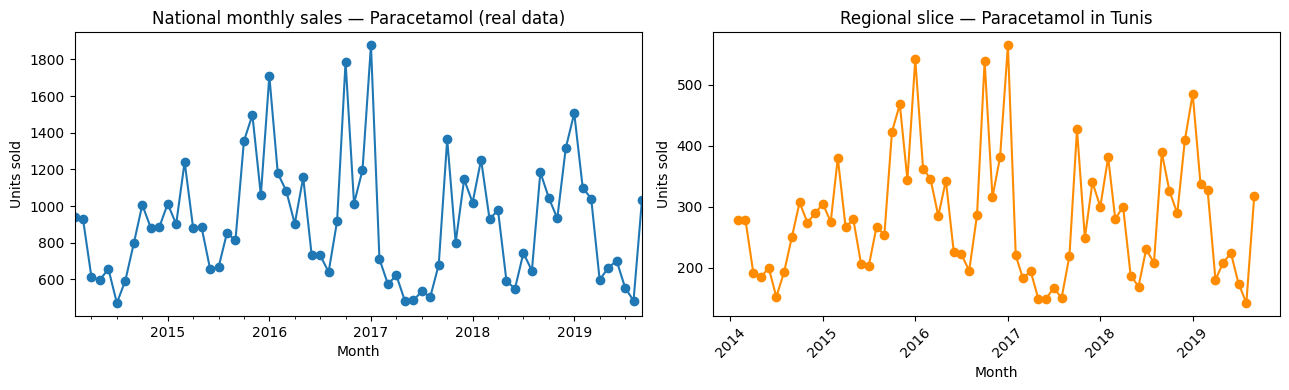

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

national_monthly["Paracetamol"].plot(ax=axes[0], marker="o", title="National monthly sales — Paracetamol (real data)")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Units sold")

example = history_df[(history_df.Region == "Tunis") & (history_df.Medicine == "Paracetamol")]
axes[1].plot(example["Month"], example["Units_Sold"], marker="o", color="darkorange")
axes[1].set_title("Regional slice — Paracetamol in Tunis")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Units sold")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 5. Forecasting model

Each `(Region, Medicine)` pair gets its own model. We fit **Holt-Winters Exponential
Smoothing** with both additive and multiplicative seasonality and keep whichever scores
lower MAPE on the holdout for that series — Exponential Smoothing is the choice because it's
what the reference project's own benchmark (see the README table linked above) found to be
the strongest performer on this dataset, beating Seasonal ARIMA, LSTM, TCN, and a Temporal
Fusion Transformer.

In [6]:
def fit_forecast_model(series: pd.Series, seasonal: str):
    return ExponentialSmoothing(
        series, trend="add", seasonal=seasonal, seasonal_periods=12
    ).fit()


def mape(forecast, actual):
    return float(np.mean(np.abs((forecast - actual) / actual)) * 100)

## 6. Backtest — additive vs. multiplicative, per series

In [7]:
backtest_rows = []

for (region, med), grp in history_df.groupby(["Region", "Medicine"]):
    s = grp.set_index("Month")["Units_Sold"].asfreq("MS")
    train, test = s.iloc[:-HOLDOUT_MONTHS], s.iloc[-HOLDOUT_MONTHS:]
    scores = {}
    for seasonal in ("add", "mul"):
        try:
            model = fit_forecast_model(train, seasonal)
            forecast = model.forecast(HOLDOUT_MONTHS)
            scores[seasonal] = mape(forecast.values, test.values)
        except Exception:
            continue
    if scores:
        best = min(scores, key=scores.get)
        backtest_rows.append([region, med, best, scores[best]])

backtest_df = pd.DataFrame(backtest_rows, columns=["Region", "Medicine", "Best_Seasonal", "MAPE"])
print(f"Backtested {len(backtest_df)} region/medicine series")
print(f"Mean MAPE:   {backtest_df.MAPE.mean():.2f}%")
print(f"Median MAPE: {backtest_df.MAPE.median():.2f}%")
print(backtest_df.Best_Seasonal.value_counts())
backtest_df.sort_values("MAPE", ascending=False).head(10)

Backtested 80 region/medicine series
Mean MAPE:   26.82%
Median MAPE: 23.38%
Best_Seasonal
add    45
mul    35
Name: count, dtype: int64


,Region,Medicine,Best_Seasonal,MAPE
62,Sfax,Salbutamol,mul,60.703200
14,Bizerte,Salbutamol,mul,60.595450
38,Monastir,Salbutamol,mul,58.838034
22,Gabès,Salbutamol,mul,58.614358
78,Tunis,Salbutamol,mul,56.921186
6,Ariana,Salbutamol,mul,52.444939
55,Nabeul,Zolpidem,add,50.394314
70,Sousse,Salbutamol,mul,49.642926
54,Nabeul,Salbutamol,mul,48.915896
30,Kairouan,Salbutamol,mul,48.177651


## 7. Forecast next month's demand for every Region x Medicine

Refit each model on the **full** history, using whichever seasonal form won that series'
backtest, and forecast one month ahead.

In [8]:
best_seasonal_map = backtest_df.set_index(["Region", "Medicine"])["Best_Seasonal"].to_dict()

forecast_rows = []

for (region, med), grp in history_df.groupby(["Region", "Medicine"]):
    s = grp.set_index("Month")["Units_Sold"].asfreq("MS")
    seasonal = best_seasonal_map.get((region, med), "add")
    model = fit_forecast_model(s, seasonal)
    next_month_pred = max(0, round(model.forecast(1).iloc[0]))
    forecast_rows.append([region, med, next_month_pred])

forecast_df = pd.DataFrame(forecast_rows, columns=["Region", "Medicine", "Predicted_Demand"])
forecast_df.head(10)

,Region,Medicine,Predicted_Demand
0,Ariana,Aspirin,6
1,Ariana,Cetirizine,5
2,Ariana,Diazepam,16
3,Ariana,Diclofenac,12
4,Ariana,Ibuprofen,7
5,Ariana,Paracetamol,85
6,Ariana,Salbutamol,21
7,Ariana,Zolpidem,1
8,Bizerte,Aspirin,7
9,Bizerte,Cetirizine,5


## 8. Current stock snapshot

Demo mode: since there's no live inventory feed yet, this simulates a plausible
`RegionalStock.csv` (what the platform's pharmacy-side stock table would export). Swap this
for a real query against the pharmacy/regional stock database in production.

In [9]:
def generate_demo_stock(forecast_df):
    rng = np.random.default_rng(7)
    stock_ratio = rng.uniform(0.55, 1.35, len(forecast_df))
    stock = (forecast_df["Predicted_Demand"] * stock_ratio).round().astype(int)
    out = forecast_df[["Region", "Medicine"]].copy()
    out["Stock"] = stock
    out["Status"] = np.select(
        [out["Stock"] < forecast_df["Predicted_Demand"] * 0.5,
         out["Stock"] < forecast_df["Predicted_Demand"]],
        ["🔴", "🟡"],
        default="🟢",
    )
    return out


import os
if not os.path.exists(REGIONAL_STOCK_PATH):
    generate_demo_stock(forecast_df).to_csv(REGIONAL_STOCK_PATH, index=False)

stock_preview = pd.read_csv(REGIONAL_STOCK_PATH)
stock_preview.head(10)

,Region,Medicine,Stock,Status
0,Ariana,Aspirin,6,🟢
1,Ariana,Cetirizine,6,🟢
2,Ariana,Diazepam,19,🟢
3,Ariana,Diclofenac,9,🟡
4,Ariana,Ibuprofen,6,🟡
5,Ariana,Paracetamol,106,🟢
6,Ariana,Salbutamol,12,🟡
7,Ariana,Zolpidem,1,🟢
8,Bizerte,Aspirin,8,🟢
9,Bizerte,Cetirizine,5,🟢


## 9. Merge with current stock + compute shortage & recommendation

Reads `RegionalStock.csv` (the `Region, Medicine, Stock, Status` file from the admin
dashboard) and combines it with the forecast to produce, for every region/medicine:

- **Expected_Shortage_Days** — estimated days until the region runs short, assuming
  consumption proceeds at the predicted monthly rate
- **Recommendation** — how many units the central pharmacy should send, rounded to the
  nearest 50

This mirrors the dashboard's *"Current stock / Predicted demand / Expected shortage /
Recommendation"* panel.

In [10]:
stock_df = pd.read_csv(REGIONAL_STOCK_PATH)

merged = forecast_df.merge(
    stock_df[["Region", "Medicine", "Stock"]], on=["Region", "Medicine"], how="left"
).rename(columns={"Stock": "Current_Stock"})

merged["Current_Stock"] = merged["Current_Stock"].fillna(0).astype(int)


def compute_shortage(row):
    daily_rate = row.Predicted_Demand / 30
    if row.Current_Stock < row.Predicted_Demand:
        days_of_stock_left = row.Current_Stock / daily_rate if daily_rate > 0 else 0
        shortage_days = max(1, round(30 - days_of_stock_left))
        deficit = row.Predicted_Demand - row.Current_Stock
        recommended_units = max(50, int(round(deficit / 50.0) * 50))
        recommendation = f"Increase regional supply by ~{recommended_units} units."
    else:
        shortage_days = 0
        recommendation = "No action needed - stock covers predicted demand."
    return pd.Series([shortage_days, recommendation])


merged[["Expected_Shortage_Days", "Recommendation"]] = merged.apply(compute_shortage, axis=1)
demand_prediction_df = merged[[
    "Region", "Medicine", "Current_Stock", "Predicted_Demand",
    "Expected_Shortage_Days", "Recommendation"
]]

demand_prediction_df.sort_values("Expected_Shortage_Days", ascending=False).head(10)

,Region,Medicine,Current_Stock,Predicted_Demand,Expected_Shortage_Days,Recommendation
55,Nabeul,Zolpidem,1,2,15,Increase regional supply by ~50 units.
39,Monastir,Zolpidem,1,2,15,Increase regional supply by ~50 units.
32,Monastir,Aspirin,3,6,15,Increase regional supply by ~50 units.
31,Kairouan,Zolpidem,1,2,15,Increase regional supply by ~50 units.
6,Ariana,Salbutamol,12,21,13,Increase regional supply by ~50 units.
37,Monastir,Paracetamol,50,90,13,Increase regional supply by ~50 units.
24,Kairouan,Aspirin,4,7,13,Increase regional supply by ~50 units.
52,Nabeul,Ibuprofen,6,10,12,Increase regional supply by ~50 units.
46,Médenine,Salbutamol,12,20,12,Increase regional supply by ~50 units.
67,Sousse,Diclofenac,8,13,12,Increase regional supply by ~50 units.


## 10. Example dashboard card (matches the spec's format)

In [11]:
row = demand_prediction_df.sort_values("Expected_Shortage_Days", ascending=False).iloc[0]

print(f"{row.Medicine}  —  {row.Region}\n")
print(f"Current stock:       {row.Current_Stock}")
print(f"Predicted demand:    {row.Predicted_Demand}")
print(f"Expected shortage:   {row.Expected_Shortage_Days} days\n")
print("⚠️ RECOMMENDATION\n")
print(row.Recommendation)

Zolpidem  —  Nabeul

Current stock:       1
Predicted demand:    2
Expected shortage:   15 days

⚠️ RECOMMENDATION

Increase regional supply by ~50 units.


## 11. Save output for the admin dashboard

In [12]:
demand_prediction_df.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {len(demand_prediction_df)} rows to {OUTPUT_PATH}")
print(f"Regions/medicines needing replenishment: {(demand_prediction_df.Expected_Shortage_Days > 0).sum()} / {len(demand_prediction_df)}")

Saved 80 rows to DemandPrediction.csv
Regions/medicines needing replenishment: 38 / 80


## Next steps to move from demo to production

- Replace `load_regional_history()`'s population-weight disaggregation with real
  per-region POS/ERP exports as soon as they exist — the national trend/seasonality used
  here is real, but the regional split is currently simulated.
- Consider per-medicine model choice: controlled substances (e.g. Diazepam, Zolpidem) may
  need tighter safety-stock thresholds than antihistamines.
- Add a **central pharmacy inventory** table so `Recommendation` can check real
  availability before promising a replenishment (per the spec's step 4–5 central-supply flow).
- If a future dataset has enough regional history, it's worth re-running the reference
  repo's fuller comparison (SARIMA / LSTM / TCN / TFT) per series rather than assuming
  Exponential Smoothing wins everywhere — it won on *this* dataset's holdout, not by law.
- Re-run the backtest cell whenever real data replaces the simulated regional split.